# Notebook 02: preprocesamiento

*Usar IA sin estar convencido: discrepancia entre uso y actitud en desarrolladores de software.* Trabajo final de especialización, Maestría en Explotación de Datos y Descubrimiento del Conocimiento, FCEyN-UBA.

Aplica la limpieza, la imputación, la codificación ordinal, las variables de presencia y la codificación *one-hot*, y genera dos archivos parquet:

1. `data/df_clean.parquet`: todos los desarrolladores profesionales (154.911 filas).
2. `data/df_clean_users.parquet`: solo quienes usan IA (80.369 filas).

El código está en `scripts/pipeline.py`.

## 1. Preparación

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import importlib.util
spec = importlib.util.spec_from_file_location("pipeline", ROOT / "scripts" / "pipeline.py")
pipeline = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pipeline)

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"Etiquetas de la variable a predecir: {pipeline.TARGET_LABELS}")
print(f"DEVTYPE_REMAP = {pipeline.DEVTYPE_REMAP}")

Etiquetas de la variable a predecir: {1: 'Sin discrepancia', 0: 'Con discrepancia uso-actitud'}
DEVTYPE_REMAP = {'Engineer, data': 'Data engineer', 'Data scientist': 'Data scientist or machine learning specialist', 'AI/ML engineer': 'Data scientist or machine learning specialist', 'DevOps engineer or professional': 'DevOps specialist', 'Database administrator or engineer': 'Database administrator', 'Architect, software or solutions': 'Other'}


## 2. Dataset con todos los desarrolladores profesionales

`pipeline.construir_dataset(restrict_to_users=False)`:
1. carga los tres CSV originales y unifica su formato;
2. construye la variable a predecir;
3. filtra a quienes responden `MainBranch == 'I am a developer by profession'`;
4. unifica las categorías que cambian entre ediciones (empleo, modalidad, industria, rol);
5. imputa los faltantes con la mediana o la moda de cada año y codifica las variables;
6. guarda el resultado en `data/df_clean.parquet`.

In [2]:
df_full = pipeline.construir_dataset(restrict_to_users=False, save=True)
print(f"\nFilas y columnas: {df_full.shape}")
print(f"Valores faltantes: {df_full.isnull().sum().sum()}")

Cargados: 2023=89,184  2024=65,437  2025=49,191


Desarrolladores profesionales: 154,911 (de 203,812)

Filas: 154,911
target=1 (Sin discrepancia): 63,074 (40.7%)
target=0 (Con discrepancia uso-actitud): 91,837 (59.3%)

Por año:
             count    sum   mean
survey_year                     
2023         67237  25144  0.374
2024         50207  22695  0.452
2025         37467  15235  0.407
Descartadas por >40.0% nulos: ['JobSat', 'Industry']
Nulos después de imputar: 36173



Guardado data/df_clean.parquet (2.3 MB, 154,911 filas, 91 columnas)

Filas y columnas: (154911, 91)
Valores faltantes: 0


## 3. Dataset con los usuarios de IA

El mismo proceso con `restrict_to_users=True`, que se queda con quienes responden `AISelect = Yes`.

In [3]:
df_users = pipeline.construir_dataset(restrict_to_users=True, save=True)
print(f"\nFilas y columnas: {df_users.shape}")
print(f"Valores faltantes: {df_users.isnull().sum().sum()}")

Cargados: 2023=89,184  2024=65,437  2025=49,191


Desarrolladores profesionales: 154,911 (de 203,812)
Usuarios de IA: 80,369 (de 154,911)

Filas: 80,369
target=1 (Sin discrepancia): 63,074 (78.5%)
target=0 (Con discrepancia uso-actitud): 17,295 (21.5%)

Por año:
             count    sum   mean
survey_year                     
2023         29697  25144  0.847
2024         29638  22695  0.766
2025         21034  15235  0.724
Descartadas por >40.0% nulos: ['JobSat']


Nulos después de imputar: 13664



Guardado data/df_clean_users.parquet (1.3 MB, 80,369 filas, 99 columnas)

Filas y columnas: (80369, 99)
Valores faltantes: 0


## 4. Comparación de los dos datasets

In [4]:
comparativa = pd.DataFrame({
    "Métrica": [
        "Filas",
        "Columnas",
        "Tamaño (MB)",
        "Sin discrepancia (valor 1)",
        "Con discrepancia (valor 0)",
        "% sin discrepancia",
    ],
    "Todos (df_clean.parquet)": [
        f"{len(df_full):,}",
        df_full.shape[1],
        f"{(pipeline.output_path(False).stat().st_size / 1024**2):.1f}",
        f"{df_full['target'].sum():,}",
        f"{(1-df_full['target']).sum():,}",
        f"{df_full['target'].mean() * 100:.1f}",
    ],
    "Usuarios (df_clean_users.parquet)": [
        f"{len(df_users):,}",
        df_users.shape[1],
        f"{(pipeline.output_path(True).stat().st_size / 1024**2):.1f}",
        f"{df_users['target'].sum():,}",
        f"{(1-df_users['target']).sum():,}",
        f"{df_users['target'].mean() * 100:.1f}",
    ],
})
comparativa

,Métrica,Todos (df_clean.parquet),Usuarios (df_clean_users.parquet)
0,Filas,"154,911","80,369"
1,Columnas,91,99
2,Tamaño (MB),2.3,1.3
3,Sin discrepancia (valor 1),"63,074","63,074"
4,Con discrepancia (valor 0),"91,837","17,295"
5,% sin discrepancia,40.7,78.5


**Lectura.** Al restringir a usuarios de IA:
- Las filas bajan de 155k a ~80k.
- La distribución de la variable a predecir se invierte: de 41 % sin discrepancia y 59 % con discrepancia a 78,5 % y 21,5 %.
- Al filtrar a quienes usan IA se eliminan los no usuarios, que en el conjunto completo caen todos en la clase con discrepancia.

## 5. Variable a predecir por año

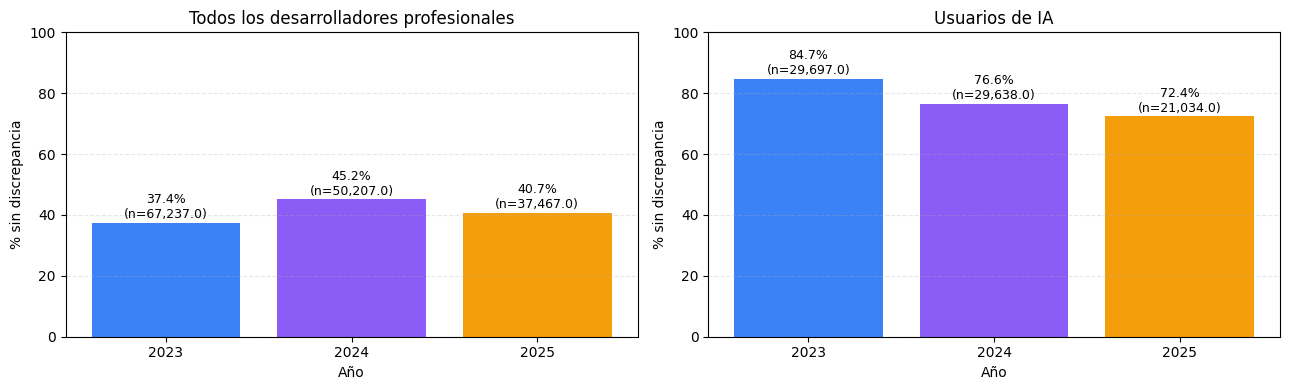

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, df, title in [(axes[0], df_full, "Todos los desarrolladores profesionales"),
                       (axes[1], df_users, "Usuarios de IA")]:
    dist = df.groupby("survey_year")["target"].agg(["count", "mean"])
    dist["mean_pct"] = dist["mean"] * 100
    ax.bar(dist.index.astype(str), dist["mean_pct"], color=["#3b82f6", "#8b5cf6", "#f59e0b"])
    ax.set_ylabel("% sin discrepancia")
    ax.set_xlabel("Año")
    ax.set_title(title)
    ax.set_ylim(0, 100)
    for i, (_, row) in enumerate(dist.iterrows()):
        ax.text(i, row["mean_pct"] + 1.5, f"{row['mean_pct']:.1f}%\n(n={row['count']:,})",
                ha="center", fontsize=9)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

**Observación.** En el conjunto completo, la tasa sin discrepancia va de 37 % (2023) a 45 % (2024) y 41 % (2025). Entre usuarios de IA arranca alta (85 % en 2023) y baja a 72 % en 2025: la discrepancia crece entre usuarios.

## 6. Variables finales por grupo

Las columnas del dataset de usuarios agrupadas según su origen.

Columnas por grupo:
Lenguaje                           21
Entorno de desarrollo              16
Rol                                13
Base de datos                      11
Plataforma                         10
Industria                           8
Región                              6
Experiencia, educación y tamaño     4
Tipo de empleo                      3
Modalidad de trabajo                3
Contribuidor o gestor               2
Año de la encuesta                  1
Variable a predecir                 1


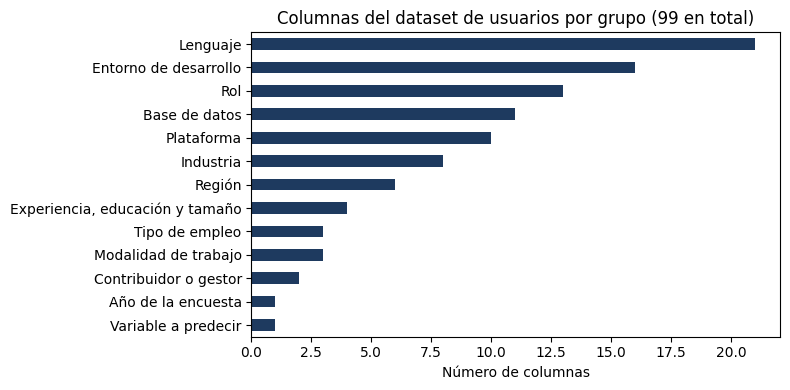

In [6]:
def familia(col):
    if col == "target":
        return "Variable a predecir"
    if col == "survey_year":
        return "Año de la encuesta"
    if col.startswith("lang_"):
        return "Lenguaje"
    if col.startswith("db_"):
        return "Base de datos"
    if col.startswith("plat_"):
        return "Plataforma"
    if col.startswith("env_"):
        return "Entorno de desarrollo"
    if col.startswith("Employment_"):
        return "Tipo de empleo"
    if col.startswith("RemoteWork_"):
        return "Modalidad de trabajo"
    if col.startswith("ICorPM_"):
        return "Contribuidor o gestor"
    if col.startswith("Region_"):
        return "Región"
    if col.startswith("DevType_"):
        return "Rol"
    if col.startswith("Industry_"):
        return "Industria"
    if col.endswith("_count"):
        return "Cantidad"
    return "Experiencia, educación y tamaño"

fam = pd.Series([familia(c) for c in df_users.columns]).value_counts()
print("Columnas por grupo:")
print(fam.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
fam.sort_values().plot(kind="barh", ax=ax, color="#1E3A5F")
ax.set_xlabel("Número de columnas")
ax.set_title(f"Columnas del dataset de usuarios por grupo ({df_users.shape[1]} en total)")
plt.tight_layout()
plt.show()

## 7. Siguiente paso

- `notebooks/03_eda.ipynb`: análisis exploratorio (H1, H2, variación por año, grupos y brecha entre uso y actitud).
- `notebooks/04_modelado.ipynb`: modelado supervisado, SHAP y análisis temporal.